![The Bridge - Matplotlib](../img/banner_thebridge_matplotlib.png)

# Visualización con Matplotlib: Histogramas y diagramas de caja

Vamos a ver de forma sencilla cómo hacer dos de los gráficos más habituales en los análisis univariantes: los histogramas y los boxplots.

In [1]:
# %matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
plt.style.use('seaborn-v0_8')

### Histogramas

Tan sencillo como:

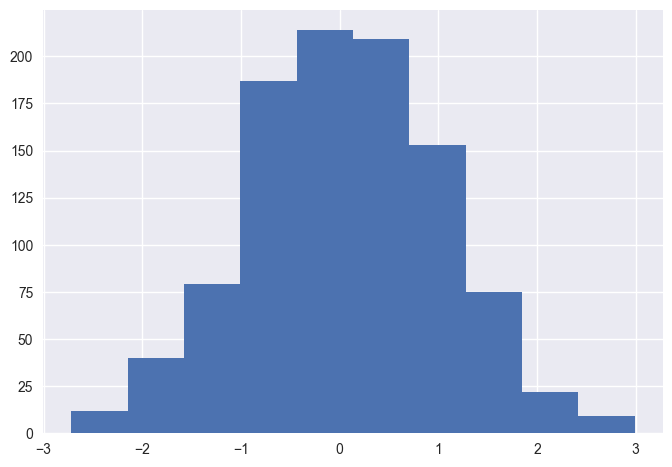

In [2]:
data = np.random.randn(1000)

plt.hist(data);


La función ``hist()`` tiene muchas opciones para ajustar tanto el cálculo como la visualización; aquí tienes un ejemplo de un histograma más personalizado (en el que tocamos el número de columnas `bins`, la transparencia y el color):


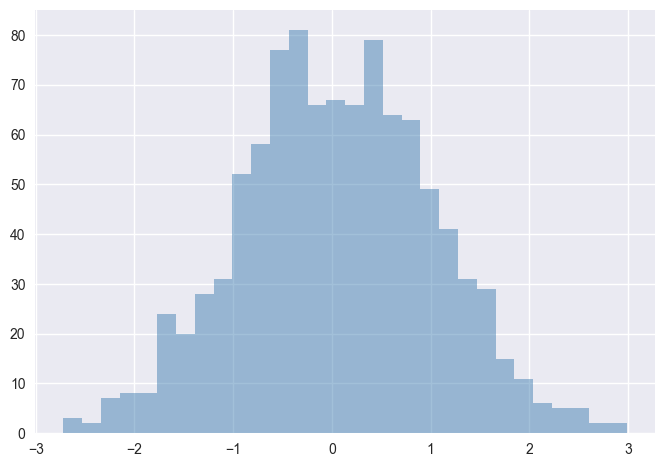

In [3]:
plt.hist(data, bins=30, alpha=0.5, color='steelblue');

La transparencia es particularmente interesante para comparar histogramas o mostrar dicha comparación (y aprovecho para enseñarte un truco para cuando tengas argumentos repetidos que poner en tus llamadas a función):

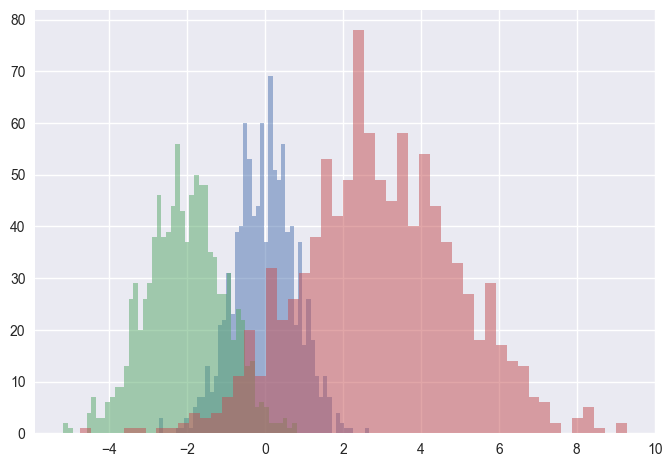

In [4]:
x1 = np.random.normal(0, 0.8, 1000)
x2 = np.random.normal(-2, 1, 1000)
x3 = np.random.normal(3, 2, 1000)

# Truco: guardamos los argumentos repetidos en un diccionario y los desempaquetamos con **
kwargs = dict(alpha=0.5, bins=50)

plt.hist(x1, **kwargs)
plt.hist(x2, **kwargs)
plt.hist(x3, **kwargs);

Es también el momento de enseñarte a capturar los límites de esos *bins*:

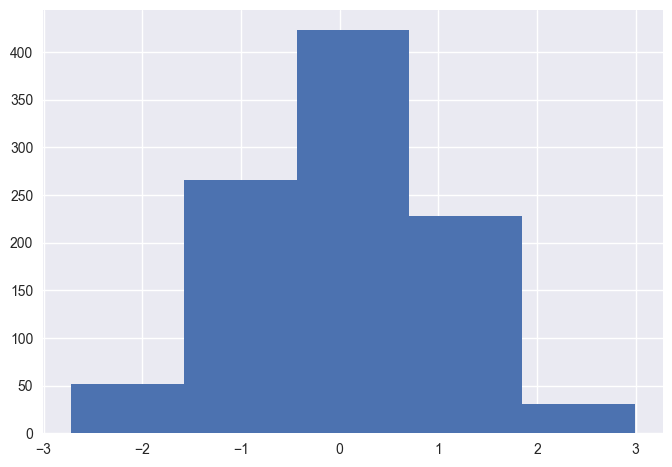

In [5]:
limites = plt.hist(data, bins=5)

``plt.hist`` devuelve una tupla en la que el primer valor son los conteos y el segundo los límites de las barras (el tercero son los objetos gráficos de las barras):

In [6]:
conteos = limites[0]
bordes = limites[1]
print(conteos)
print(bordes)

[ 52. 266. 423. 228.  31.]
[-2.71996306 -1.57786383 -0.4357646   0.70633462  1.84843385  2.99053307]


Si solo quieres calcular el histograma (contar cuántos puntos caen en cada intervalo) sin pintarlo, tienes la función ``np.histogram()``:

In [7]:
counts, bin_edges = np.histogram(data, bins=5)
print(counts)
print(bin_edges)

[ 52 266 423 228  31]
[-2.71996306 -1.57786383 -0.4357646   0.70633462  1.84843385  2.99053307]


### Boxplots

Los diagramas de caja eran esos diagramas en los que resumíamos las medidas de posición y añadíamos una posible forma de obtener valores anómalos, extremos o outliers. En forma de diagrama:

```text
     Q1-1.5IQR   Q1  mediana  Q3   Q3+1.5IQR
                  |-----:-----|
  o      |--------|     :     |--------|    o  o
                  |-----:-----|
flier             <----------->            fliers/outlier
                       IQR

```

Donde IQR es el rango intercuartílico (la diferencia entre el valor de Q3 o tercer cuartil o percentil 75 y el valor de Q1 o primer cuartil, o percentil 25).

En matplotlib:

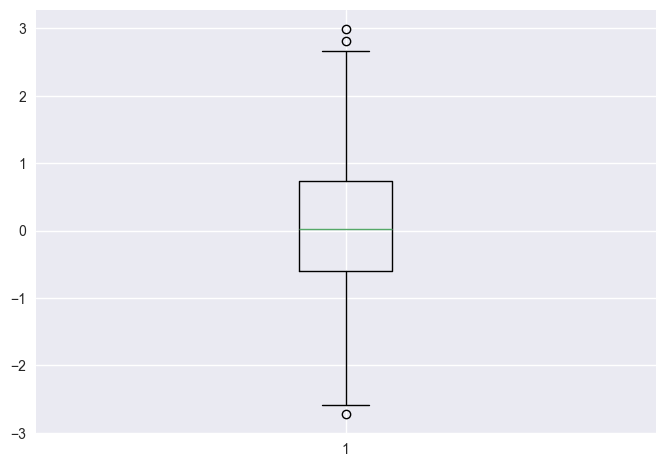

In [8]:
plt.boxplot(data);

En el caso de matplotlib empleamos por defecto diagramas de caja verticales. Pero podemos cambiarlo con `orientation='horizontal'` (en versiones anteriores a Matplotlib 3.10 el argumento era `vert=False`, que ahora está en desuso):

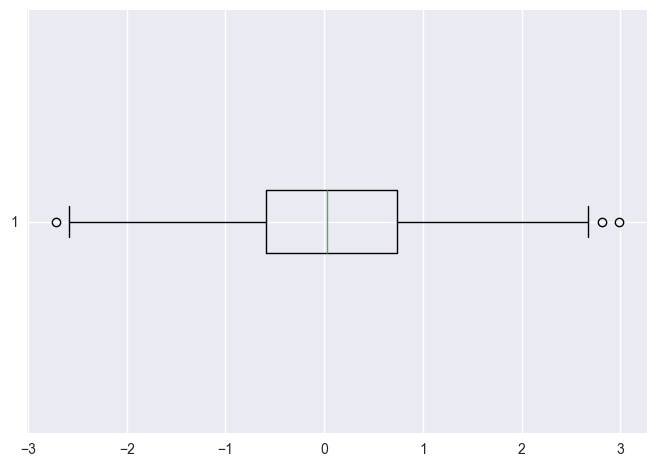

In [9]:
plt.boxplot(data, orientation='horizontal');

Y podemos mostrar varios juntos, por ejemplo las tres distribuciones del apartado de histogramas:

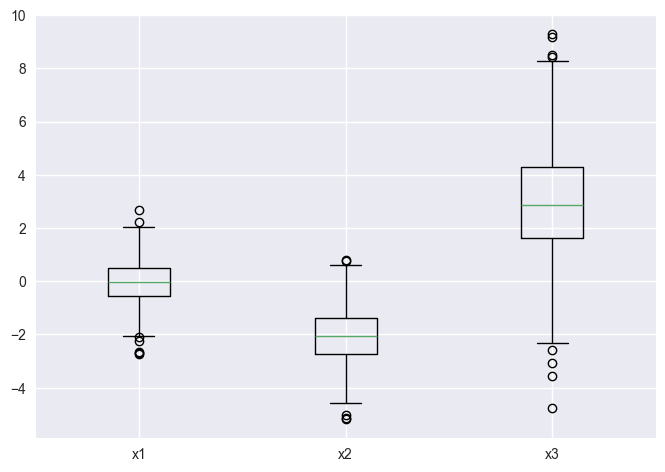

In [10]:
plt.boxplot([x1, x2, x3], tick_labels=['x1', 'x2', 'x3']);

O con datos reales: la edad de los pasajeros del titanic según su clase:

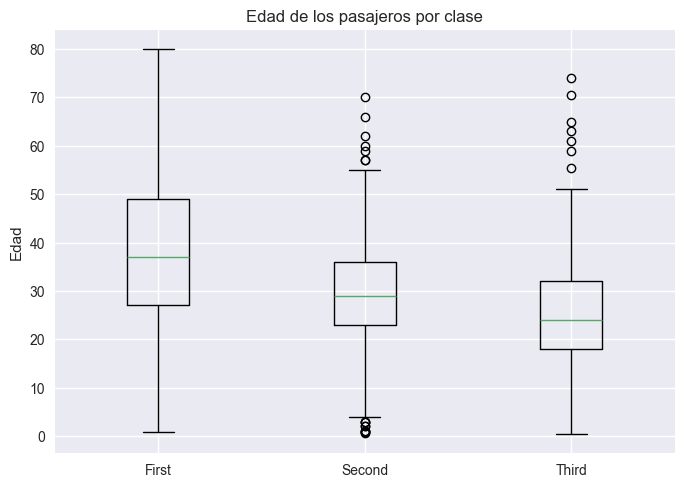

In [11]:
df_titanic = pd.read_csv("../data/titanic.csv")

clases = ['First', 'Second', 'Third']
edades = [df_titanic.loc[df_titanic['class'] == c, 'age'].dropna() for c in clases]

plt.boxplot(edades, tick_labels=clases)
plt.title("Edad de los pasajeros por clase")
plt.ylabel("Edad");